# Faz 5 — Değerlendirme Protokolünün Denetimli Sonuçlara Etkisi

## Denetimden gelen bulgular

| Bulgu | Ölçüm |
|---|---|
| gafgyt:tcp ve gafgyt:udp dosya içi tekrar | 1,8 milyon satırın %0,1'i tekil |
| gafgyt saldırıları cihazlar arası ortak | 36/36 çiftte %86--100 |
| Mirai saldırıları üç kümede ortak | küme içi %89--100, kümeler arası yok |
| İyi huylu trafik | cihaza özgü (Faz 1: %98 ayırt edilebilir) |
| İyi huylu ↔ saldırı birebir çakışma | yok |

## Bu notebook'un sorusu

Literatürdeki çalışmaların çoğu N-BaIoT üzerinde **denetimli sınıflandırma** yapar ve
genellikle **rastgele satır bölmesi** kullanır. Bu yapı altında bildirilen başarım ne
kadar gerçektir?

Aynı modeller beş farklı bölmeyle eğitilip test edilir. Her bölmede ayrıca **test
satırlarının yüzde kaçının eğitimde birebir bulunduğu** ölçülür. Bu oran, başarım
farklarının doğrudan açıklamasıdır.

### Bölmeler

| Kod | Bölme | Ne test ediyor |
|---|---|---|
| **S1** | Rastgele satır (tüm cihazlar havuzlanmış) | Literatürde yaygın uygulama |
| **S2** | Önce küresel tekilleştirme, sonra rastgele | Yalnızca birebir tekrarın etkisi |
| **S3** | Zamansal (her dosya içinde ilk %70 / son %30) | Ardışık pencere sızıntısının etkisi |
| **S4** | Bir cihaz dışarıda (9 kat) | Cihazlar arası genelleme --- *ama saldırılar paylaşılıyor* |
| **S5** | Bir Mirai kümesi dışarıda (3 kat) | **Gerçekten görülmemiş saldırı yakalaması** |

### S5'in önemi

Bir Mirai kümesi (örneğin iki Provision kamerası) tamamen test tarafına ayrıldığında:

- Bu cihazların **gafgyt** verisi eğitimdeki diğer cihazlarla aynıdır → sızıntı sürer.
- Bu cihazların **Mirai** verisi başka hiçbir cihazda yoktur → gerçekten görülmemiştir.

Aynı bölme içinde iki aile farklı davranmalıdır. Bu, sızıntının etkisini aynı model ve
aynı test cihazları üzerinde izole eder.

---

**Not:** Bu notebook TensorFlow yüklemez; yalnızca scikit-learn kullanır. Önceki
CUDA/OpenMP çakışması burada yaşanmaz.

## 0. Kurulum

In [1]:
import sys, os, glob, time, json, pickle, warnings
from collections import defaultdict

_PYLIBS = os.path.expanduser("~/work/pylibs")
if os.path.isdir(_PYLIBS) and _PYLIBS not in sys.path:
    sys.path.insert(0, _PYLIBS)
os.environ["OMP_NUM_THREADS"] = "8"

import numpy as np, pandas as pd
import matplotlib; import matplotlib.pyplot as plt; import seaborn as sns
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import f1_score, matthews_corrcoef, recall_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="talk")
matplotlib.rcParams["figure.dpi"] = 60
matplotlib.rcParams["savefig.dpi"] = 300
matplotlib.rcParams["savefig.bbox"] = "tight"

KOK = os.path.expanduser("~/work/IoT_Botnet/veri/nbaiot")
OUT = os.path.expanduser("~/work/IoT_Botnet/faz5_ciktilar")
for s in ("figures", "tables"): os.makedirs(f"{OUT}/{s}", exist_ok=True)
CKPT = f"{OUT}/faz5_checkpoint.pkl"

SEED = 42
EGITIM_UST = 150_000      # egitim kumesi ust siniri (hiz icin)
TEST_UST   = 150_000      # test kumesi ust siniri
N_JOBS     = 8

MIRAI_KUME = {
    "Danmini_Doorbell": "K1", "Philips_B120N10_Baby_Monitor": "K1",
    "Ecobee_Thermostat": "K2",
    "SimpleHome_XCS7_1002_WHT_Security_Camera": "K2",
    "SimpleHome_XCS7_1003_WHT_Security_Camera": "K2",
    "Provision_PT_737E_Security_Camera": "K3",
    "Provision_PT_838_Security_Camera": "K3",
}

def savefig(a):
    plt.savefig(f"{OUT}/figures/{a}.png"); plt.show()
print("Cikti:", OUT)

Cikti: /home/jovyan/work/IoT_Botnet/faz5_ciktilar


## 1. Veri yükleme

Tüm veri yükleniyor (7 milyon satır, float32 ile yaklaşık 3,3 GB). Her satır için
**içerik özeti** (hash) hesaplanıyor; birebir aynı satırlar aynı özeti verir. Bu özetler
bölmeler arası çakışmayı ölçmek için kullanılıyor.

In [2]:
def bilgi(y):
    p = os.path.relpath(y, KOK).split(os.sep)
    if len(p) == 2: return p[0], "benign", "benign"
    return p[0], p[1].replace("_attacks", ""), os.path.splitext(p[-1])[0]

dosyalar = [f for f in sorted(glob.glob(f"{KOK}/**/*.csv", recursive=True))
            if "demonstrate" not in f]

t0 = time.time(); parca = []
for f in dosyalar:
    c, a, t = bilgi(f)
    df = pd.read_csv(f, dtype="float32")
    df["cihaz"] = c; df["aile"] = a; df["tur"] = t
    df["sinif"] = "benign" if a == "benign" else f"{a}:{t}"
    df["satir_no"] = np.arange(len(df), dtype="int32")
    parca.append(df)
V = pd.concat(parca, ignore_index=True); del parca

OZN = [c for c in V.columns if c not in ("cihaz","aile","tur","sinif","satir_no")]
V["kotu"] = (V.aile != "benign").astype("int8")
V["hash"] = pd.util.hash_pandas_object(V[OZN], index=False).to_numpy()
CIHAZLAR = sorted(V.cihaz.unique())
SINIFLAR = sorted(V.sinif.unique())

print(f"Yuklendi: {V.shape} ({time.time()-t0:.0f} s, "
      f"{V.memory_usage(deep=True).sum()/1e9:.1f} GB)")
print(f"Tekil satir: {V.hash.nunique():,} / {len(V):,} "
      f"(%{100*V.hash.nunique()/len(V):.1f})")
print(f"Sinif sayisi: {len(SINIFLAR)}")

Yuklendi: (7062606, 122) (34 s, 3.9 GB)
Tekil satir: 2,278,176 / 7,062,606 (%32.3)
Sinif sayisi: 11


## 2. Bölmelerin tanımı

In [3]:
rs = np.random.RandomState(SEED)

def kirp(idx, ust, rs):
    return idx if len(idx) <= ust else rs.choice(idx, ust, replace=False)

def bolme_S1():
    idx = np.arange(len(V)); p = rs.permutation(idx); k = int(0.7*len(p))
    return [("S1", "-", p[:k], p[k:])]

def bolme_S2():
    tekil = V.drop_duplicates("hash").index.to_numpy()
    p = rs.permutation(tekil); k = int(0.7*len(p))
    return [("S2", "-", p[:k], p[k:])]

def bolme_S3():
    tr, te = [], []
    for _, g in V.groupby(["cihaz","sinif"], sort=False):
        g = g.sort_values("satir_no"); k = int(0.7*len(g))
        tr.append(g.index[:k].to_numpy()); te.append(g.index[k:].to_numpy())
    return [("S3", "-", np.concatenate(tr), np.concatenate(te))]

def bolme_S4():
    out = []
    for c in CIHAZLAR:
        te = V.index[V.cihaz == c].to_numpy()
        tr = V.index[V.cihaz != c].to_numpy()
        out.append(("S4", c, tr, te))
    return out

def bolme_S5():
    out = []
    for k in ["K1","K2","K3"]:
        kume = [c for c, v in MIRAI_KUME.items() if v == k]
        te = V.index[V.cihaz.isin(kume)].to_numpy()
        tr = V.index[~V.cihaz.isin(kume)].to_numpy()
        out.append(("S5", k, tr, te))
    return out

BOLMELER = bolme_S1() + bolme_S2() + bolme_S3() + bolme_S4() + bolme_S5()
print(f"{len(BOLMELER)} bolme/kat tanimlandi:")
for b, k, tr, te in BOLMELER:
    print(f"  {b}  {str(k)[:34]:<36} egitim={len(tr):>9,}  test={len(te):>9,}")

15 bolme/kat tanimlandi:
  S1  -                                    egitim=4,943,824  test=2,118,782
  S2  -                                    egitim=1,594,723  test=  683,453
  S3  -                                    egitim=4,943,780  test=2,118,826
  S4  Danmini_Doorbell                     egitim=6,044,308  test=1,018,298
  S4  Ecobee_Thermostat                    egitim=6,226,730  test=  835,876
  S4  Ennio_Doorbell                       egitim=6,707,106  test=  355,500
  S4  Philips_B120N10_Baby_Monitor         egitim=5,963,929  test=1,098,677
  S4  Provision_PT_737E_Security_Camera    egitim=6,234,346  test=  828,260
  S4  Provision_PT_838_Security_Camera     egitim=6,225,715  test=  836,891
  S4  Samsung_SNH_1011_N_Webcam            egitim=6,687,384  test=  375,222
  S4  SimpleHome_XCS7_1002_WHT_Security_   egitim=6,199,550  test=  863,056
  S4  SimpleHome_XCS7_1003_WHT_Security_   egitim=6,211,780  test=  850,826
  S5  K1                                   egitim=4,945,631  te

## 3. Sızıntı ölçümü (eğitim gerektirmez)

Her bölme için: test satırlarının yüzde kaçının eğitim kümesinde birebir bulunduğu.
Bu, modelin "görmeden" değil "hatırlayarak" doğru tahmin edebileceği satırların oranıdır.

In [4]:
H = V["hash"].to_numpy()
siz = []
for b, k, tr, te in BOLMELER:
    tr_h = np.unique(H[tr])
    te_ici = np.isin(H[te], tr_h)
    s = {"bolme": b, "kat": k, "test_satir": len(te),
         "sizinti_tum_%": round(100*te_ici.mean(), 3)}
    for aile in ["benign", "gafgyt", "mirai"]:
        m = (V.aile.to_numpy()[te] == aile)
        s[f"sizinti_{aile}_%"] = round(100*te_ici[m].mean(), 3) if m.any() else np.nan
    siz.append(s)
SIZ = pd.DataFrame(siz)
SIZ.to_csv(f"{OUT}/tables/f5_tablo1_sizinti.csv", index=False)
oz = SIZ.groupby("bolme")[[c for c in SIZ.columns if c.startswith("sizinti")]].mean().round(2)
print("Test satirlarinin egitimde birebir bulunma orani (%):\n")
print(oz.to_string())
print("\nS5 satirlarina ozellikle bak: gafgyt yuksek, mirai sifira yakin olmali.")

Test satirlarinin egitimde birebir bulunma orani (%):

       sizinti_tum_%  sizinti_benign_%  sizinti_gafgyt_%  sizinti_mirai_%
bolme                                                                    
S1             80.67             10.26             99.80            76.52
S2              0.00              0.00              0.00             0.00
S3             30.50             10.66             66.34             5.79
S4             90.59              0.01             99.89            97.59
S5             34.82              0.00             99.86             0.00

S5 satirlarina ozellikle bak: gafgyt yuksek, mirai sifira yakin olmali.


## 4. Modeller ve eğitim döngüsü

In [5]:
def modeller():
    return {
        "RandomForest": RandomForestClassifier(n_estimators=150, max_depth=None,
                                               n_jobs=N_JOBS, random_state=SEED),
        "HistGB": HistGradientBoostingClassifier(max_iter=200, random_state=SEED),
        "LogReg": make_pipeline(StandardScaler(),
                                LogisticRegression(max_iter=300)),
    }

def degerlendir(y_bin, p_bin, y_cok, p_cok, aile):
    r = {"F1_ikili": f1_score(y_bin, p_bin, zero_division=0),
         "MCC_ikili": matthews_corrcoef(y_bin, p_bin),
         "F1_makro_cok": f1_score(y_cok, p_cok, average="macro", zero_division=0)}
    for a in ["gafgyt", "mirai"]:
        m = (aile == a)
        r[f"yakalama_{a}"] = float((p_bin[m] == 1).mean()) if m.any() else np.nan
        # cok sinifli: dogru TURU bulma orani
        r[f"tur_dogrulugu_{a}"] = float((p_cok[m] == y_cok[m]).mean()) if m.any() else np.nan
    m = (aile == "benign")
    r["yanlis_alarm"] = float((p_bin[m] == 1).mean()) if m.any() else np.nan
    return r

In [6]:
if os.path.exists(CKPT):
    with open(CKPT,"rb") as f: SON = pickle.load(f)
    print(f"Onceki kayit: {len(SON)} sonuc")
else:
    SON = []
tamam = {(r["bolme"], r["kat"], r["model"]) for r in SON}

X_all = V[OZN].to_numpy(dtype="float32")
y_bin_all = V.kotu.to_numpy()
y_cok_all = V.sinif.to_numpy()
aile_all  = V.aile.to_numpy()

t0 = time.time()
for b, k, tr, te in BOLMELER:
    rsb = np.random.RandomState(SEED)
    tr_s = kirp(tr, EGITIM_UST, rsb); te_s = kirp(te, TEST_UST, rsb)
    for mad, mod in modeller().items():
        if (b, k, mad) in tamam: continue
        t1 = time.time()
        # ikili
        mb = modeller()[mad]; mb.fit(X_all[tr_s], y_bin_all[tr_s])
        pb = mb.predict(X_all[te_s])
        # cok sinifli
        mc = modeller()[mad]; mc.fit(X_all[tr_s], y_cok_all[tr_s])
        pc = mc.predict(X_all[te_s])
        r = {"bolme": b, "kat": k, "model": mad, "sure_s": round(time.time()-t1, 1),
             **degerlendir(y_bin_all[te_s], pb, y_cok_all[te_s], pc, aile_all[te_s])}
        SON.append(r)
        print(f"  {b} {str(k)[:22]:<24}{mad:<14} F1={r['F1_ikili']:.4f}  "
              f"MCC={r['MCC_ikili']:.4f}  F1cok={r['F1_makro_cok']:.4f}  "
              f"({r['sure_s']}s)")
    with open(CKPT,"wb") as f: pickle.dump(SON, f)

print(f"\nToplam sure: {(time.time()-t0)/60:.1f} dk")
R = pd.DataFrame(SON)
R.to_csv(f"{OUT}/tables/f5_ham_sonuclar.csv", index=False)

  S1 -                       RandomForest   F1=1.0000  MCC=0.9994  F1cok=0.9975  (11.6s)
  S1 -                       HistGB         F1=0.9999  MCC=0.9992  F1cok=0.9976  (12.5s)
  S1 -                       LogReg         F1=0.9997  MCC=0.9966  F1cok=0.8079  (10.3s)
  S2 -                       RandomForest   F1=1.0000  MCC=0.9998  F1cok=0.8404  (11.6s)
  S2 -                       HistGB         F1=1.0000  MCC=0.9998  F1cok=0.8089  (4.5s)
  S2 -                       LogReg         F1=0.9998  MCC=0.9989  F1cok=0.7390  (12.8s)
  S3 -                       RandomForest   F1=0.9999  MCC=0.9992  F1cok=0.9037  (11.7s)
  S3 -                       HistGB         F1=0.9998  MCC=0.9978  F1cok=0.8865  (18.5s)
  S3 -                       LogReg         F1=0.9996  MCC=0.9953  F1cok=0.7394  (11.3s)
  S4 Danmini_Doorbell        RandomForest   F1=1.0000  MCC=0.9997  F1cok=0.9979  (11.4s)
  S4 Danmini_Doorbell        HistGB         F1=1.0000  MCC=0.9996  F1cok=0.9980  (18.4s)
  S4 Danmini_Doorbell 

## 5. Ana tablo: bölmeye göre başarım

In [7]:
R = pd.DataFrame(SON)
METR = ["F1_ikili","MCC_ikili","F1_makro_cok","yakalama_gafgyt","yakalama_mirai",
        "tur_dogrulugu_gafgyt","tur_dogrulugu_mirai","yanlis_alarm"]
ana = R.groupby(["bolme","model"])[METR].mean().round(4)
ana.to_csv(f"{OUT}/tables/f5_tablo2_ana.csv")
print(ana.to_string())

                    F1_ikili  MCC_ikili  F1_makro_cok  yakalama_gafgyt  yakalama_mirai  tur_dogrulugu_gafgyt  tur_dogrulugu_mirai  yanlis_alarm
bolme model                                                                                                                                    
S1    HistGB          0.9999     0.9992        0.9976           0.9999          1.0000                0.9925               0.9999        0.0008
      LogReg          0.9997     0.9966        0.8079           0.9995          0.9999                0.6291               0.9537        0.0034
      RandomForest    1.0000     0.9994        0.9975           0.9998          1.0000                0.9923               0.9999        0.0003
S2    HistGB          1.0000     0.9998        0.8089           0.9993          1.0000                0.9837               0.9946        0.0000
      LogReg          0.9998     0.9989        0.7390           0.9974          0.9999                0.8074               0.9551       

       F1_makro_cok  MCC_ikili  sizinti_%
bolme                                    
S1           0.9975     0.9994    80.6660
S2           0.8404     0.9998     0.0000
S3           0.9037     0.9992    30.5030
S4           0.9320     0.9986    90.5906
S5           0.9568     0.9939    34.8163


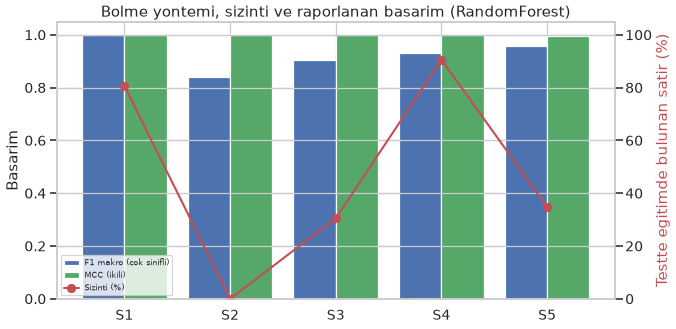

In [8]:
# ---- Sizinti ile basarim yan yana --------------------------------------
siz_ort = SIZ.groupby("bolme").sizinti_tum_.mean() if "sizinti_tum_" in SIZ else \
          SIZ.groupby("bolme")["sizinti_tum_%"].mean()
rf = R[R.model == "RandomForest"].groupby("bolme")[["F1_makro_cok","MCC_ikili"]].mean()
birlesik = rf.join(siz_ort.rename("sizinti_%")).reindex(["S1","S2","S3","S4","S5"])
birlesik.to_csv(f"{OUT}/tables/f5_tablo3_sizinti_ve_basarim.csv")
print(birlesik.round(4).to_string())

fig, ax1 = plt.subplots(figsize=(12, 6))
x = np.arange(len(birlesik))
ax1.bar(x - 0.2, birlesik.F1_makro_cok, 0.4, color="#4c72b0", label="F1 makro (cok sinifli)")
ax1.bar(x + 0.2, birlesik.MCC_ikili, 0.4, color="#55a868", label="MCC (ikili)")
ax1.set_ylim(0, 1.05); ax1.set_xticks(x); ax1.set_xticklabels(birlesik.index)
ax1.set_ylabel("Basarim")
ax2 = ax1.twinx()
ax2.plot(x, birlesik["sizinti_%"], "o-", color="#c44e52", lw=2.5, ms=10,
         label="Sizinti (%)")
ax2.set_ylabel("Testte egitimde bulunan satir (%)", color="#c44e52")
ax2.set_ylim(0, 105)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1+h2, l1+l2, fontsize=9, loc="lower left")
plt.title("Bolme yontemi, sizinti ve raporlanan basarim (RandomForest)")
savefig("f5_fig01_sizinti_basarim")

## 6. S5 --- aynı bölmede iki aile

Burada sızıntının etkisi, aynı model ve aynı test cihazları üzerinde izole ediliyor.

                  yakalama_gafgyt  yakalama_mirai  tur_dogrulugu_gafgyt  tur_dogrulugu_mirai
kat model                                                                                   
K1  HistGB                 1.0000          1.0000                0.9929               0.9474
    LogReg                 0.9996          1.0000                0.6401               0.8699
    RandomForest           0.9998          1.0000                0.9928               0.9998
K2  HistGB                 0.9999          0.9999                0.9909               0.6982
    LogReg                 0.9996          0.9999                0.6306               0.7192
    RandomForest           0.9998          1.0000                0.9909               0.9601
K3  HistGB                 0.9999          1.0000                0.9904               0.4908
    LogReg                 0.9993          0.9999                0.6282               0.5916
    RandomForest           0.9998          1.0000                0.990

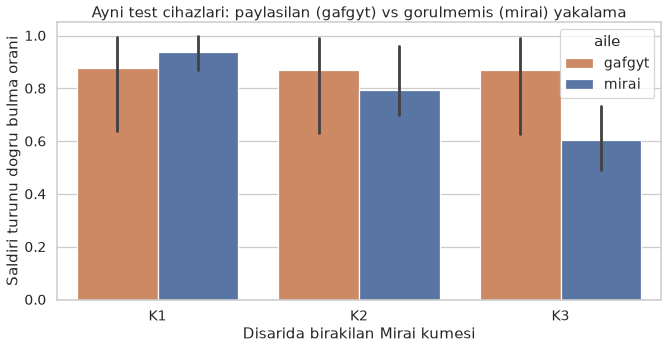

In [9]:
s5 = R[R.bolme == "S5"]
cols = ["yakalama_gafgyt","yakalama_mirai","tur_dogrulugu_gafgyt","tur_dogrulugu_mirai"]
t = s5.groupby(["kat","model"])[cols].mean().round(4)
t.to_csv(f"{OUT}/tables/f5_tablo4_S5_aileler.csv")
print(t.to_string())

s5siz = SIZ[SIZ.bolme == "S5"][["kat","sizinti_gafgyt_%","sizinti_mirai_%"]]
print("\nAyni katlarda sizinti orani:\n")
print(s5siz.to_string(index=False))

uzun = s5.melt(id_vars=["kat","model"], value_vars=["tur_dogrulugu_gafgyt","tur_dogrulugu_mirai"],
               var_name="aile", value_name="dogruluk")
uzun["aile"] = uzun.aile.str.replace("tur_dogrulugu_", "")
plt.figure(figsize=(13, 6))
sns.barplot(data=uzun, x="kat", y="dogruluk", hue="aile",
            palette={"gafgyt":"#dd8452","mirai":"#4c72b0"})
plt.ylim(0, 1.05); plt.ylabel("Saldiri turunu dogru bulma orani")
plt.xlabel("Disarida birakilan Mirai kumesi")
plt.title("Ayni test cihazlari: paylasilan (gafgyt) vs gorulmemis (mirai) yakalama")
savefig("f5_fig02_S5_aileler")

## 7. Sınıf bazlı: tcp ve udp ne kadar ayırt edilebiliyor?

In [10]:
# Zor turlerin cok sinifli dogrulugu bolmeye gore
# (ayri kosu gerektirmez: S1 ve S3 icin RF tahminleri yeniden uretilir)
def sinif_bazli(b_ad):
    b = [x for x in BOLMELER if x[0] == b_ad][0]
    _, _, tr, te = b
    rsb = np.random.RandomState(SEED)
    tr_s = kirp(tr, EGITIM_UST, rsb); te_s = kirp(te, TEST_UST, rsb)
    m = RandomForestClassifier(n_estimators=150, n_jobs=N_JOBS, random_state=SEED)
    m.fit(X_all[tr_s], y_cok_all[tr_s]); p = m.predict(X_all[te_s])
    yt = y_cok_all[te_s]
    return {s: float(((p == s) & (yt == s)).sum() / max((yt == s).sum(), 1))
            for s in SINIFLAR}

sb = pd.DataFrame({b: sinif_bazli(b) for b in ["S1","S2","S3"]}).round(4)
sb.to_csv(f"{OUT}/tables/f5_tablo5_sinif_bazli.csv")
print("Sinif bazli dogru bulma orani (RandomForest):\n")
print(sb.to_string())
print("\ngafgyt:tcp ve gafgyt:udp birbirine cok benziyor; tekillestirme sonrasi")
print("bu iki sinifi ayirt etme basarisinin nasil degistigine bakin.")

Sinif bazli dogru bulma orani (RandomForest):

                    S1      S2      S3
benign          0.9999  1.0000  0.9998
gafgyt:combo    0.9987  0.9993  1.0000
gafgyt:junk     0.9973  0.9949  0.0726
gafgyt:scan     1.0000  0.9995  1.0000
gafgyt:tcp      0.9767  0.0000  0.9988
gafgyt:udp      0.9996  0.1429  0.9988
mirai:ack       0.9998  1.0000  0.9996
mirai:scan      1.0000  1.0000  1.0000
mirai:syn       1.0000  1.0000  1.0000
mirai:udp       1.0000  0.9999  1.0000
mirai:udpplain  0.9997  0.9997  0.9984

gafgyt:tcp ve gafgyt:udp birbirine cok benziyor; tekillestirme sonrasi
bu iki sinifi ayirt etme basarisinin nasil degistigine bakin.


## 8. Özet

In [11]:
ozet = {
    "bolme_tanimlari": {
        "S1": "rastgele satir", "S2": "kuresel tekillestirme + rastgele",
        "S3": "zamansal (dosya ici)", "S4": "bir cihaz disarida",
        "S5": "bir Mirai kumesi disarida",
    },
    "sizinti_%": SIZ.groupby("bolme")["sizinti_tum_%"].mean().round(2).to_dict(),
    "RandomForest_F1_makro": R[R.model=="RandomForest"].groupby("bolme")
                              .F1_makro_cok.mean().round(4).to_dict(),
    "RandomForest_MCC": R[R.model=="RandomForest"].groupby("bolme")
                         .MCC_ikili.mean().round(4).to_dict(),
    "S5_gafgyt_vs_mirai_tur_dogrulugu": {
        "gafgyt": round(float(R[(R.bolme=="S5")].tur_dogrulugu_gafgyt.mean()), 4),
        "mirai":  round(float(R[(R.bolme=="S5")].tur_dogrulugu_mirai.mean()), 4),
    },
}
with open(f"{OUT}/tables/f5_ozet.json","w") as fh:
    json.dump(ozet, fh, indent=2, ensure_ascii=False)
print(json.dumps(ozet, indent=2, ensure_ascii=False))

import shutil
ars = shutil.make_archive(os.path.expanduser("~/work/IoT_Botnet/faz5_ciktilar"),
                          "zip", OUT)
print("\nArsiv:", ars, f"({os.path.getsize(ars)/1e6:.1f} MB)")

{
  "bolme_tanimlari": {
    "S1": "rastgele satir",
    "S2": "kuresel tekillestirme + rastgele",
    "S3": "zamansal (dosya ici)",
    "S4": "bir cihaz disarida",
    "S5": "bir Mirai kumesi disarida"
  },
  "sizinti_%": {
    "S1": 80.67,
    "S2": 0.0,
    "S3": 30.5,
    "S4": 90.59,
    "S5": 34.82
  },
  "RandomForest_F1_makro": {
    "S1": 0.9975,
    "S2": 0.8404,
    "S3": 0.9037,
    "S4": 0.932,
    "S5": 0.9568
  },
  "RandomForest_MCC": {
    "S1": 0.9994,
    "S2": 0.9998,
    "S3": 0.9992,
    "S4": 0.9986,
    "S5": 0.9939
  },
  "S5_gafgyt_vs_mirai_tur_dogrulugu": {
    "gafgyt": 0.8719,
    "mirai": 0.779
  }
}

Arsiv: /home/jovyan/work/IoT_Botnet/faz5_ciktilar.zip (0.3 MB)


---

## Koşu sonrası kontrol listesi

1. **S1'de sızıntı ve başarım ne?** Literatürdeki tipik değerlerin (≈0,99+) üretildiğini doğrular.
2. **S2'de başarım ne kadar düşüyor?** Yalnızca birebir tekrarın katkısı.
3. **S4'te sızıntı yüksek mi?** Bir cihaz dışarıda bırakılsa bile gafgyt sızıntısı sürmeli.
4. **S5'te gafgyt ve Mirai ayrışıyor mu?** Makalenin en güçlü gösterimi bu.
5. **Etki modelden bağımsız mı?** Üç model aynı örüntüyü gösteriyorsa bulgu veri setine aittir.